# Examen de Big Data – Spark ML
## Parte 2. Clasificación multiclase de deserción estudiantil con Spark ML

**Nombre:** TU NOMBRE COMPLETO  **ID:** TU ID

**Problema.** Una universidad quiere identificar de forma temprana a los estudiantes en riesgo de deserción y a los que van camino de graduarse. Se construye un modelo con Spark ML que clasifica a cada estudiante en `Dropout`, `Enrolled` o `Graduate`, y luego se publica en una app de Streamlit.

**Estructura del notebook**

| Sección | Contenido | Tareas |
|---|---|---|
| **A** | Carga, limpieza, ingeniería de características y partición | 1 a 3 |
| **B** | Pipelines, hiperparametrización y validación cruzada | 4 y 5 |
| **C** | Evaluación, selección y guardado del mejor modelo | 6 |

La tarea 7 (app en Streamlit) está en `app.py` del repositorio.

**Datos:** *Predict Students' Dropout and Academic Success* (Kaggle). Subir el CSV (`data.csv` o `dataset.csv`) al entorno de Colab antes de ejecutar.

### 0. Preparación del entorno
Se instala la **misma versión de PySpark (3.5.1)** que usará la app de Streamlit, para que el modelo guardado se pueda cargar sin incompatibilidades, y se importan las librerías que se usarán en todo el notebook.

In [1]:
!pip -q install pyspark==3.5.1

import os, re, json, time, shutil, unicodedata
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.


---
# A. Carga, limpieza, ingeniería de características y partición (tareas 1 a 3)
## Tarea 1. Carga y exploración
### 1.1 Creación de la SparkSession
Se crea la sesión con `SparkSession.builder`. Se fija **`local[4]`** y **`spark.sql.shuffle.partitions=4`** porque el dataset es pequeño (~4.400 filas): más particiones solo añaden sobrecarga y demoran el entrenamiento. Se amplía la memoria del driver a 4 GB (Colab trae poca por defecto) y se desactiva `constraintPropagation` para evitar la explosión del optimizador con tantas columnas.

In [2]:
from pyspark.sql import SparkSession, functions as F

spark = (SparkSession.builder
         .appName("dropout_sparkml")
         .master("local[4]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "4")
         .config("spark.default.parallelism", "4")
         .config("spark.sql.constraintPropagation.enabled", "false")  # evita la explosión del optimizador
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Versión de Spark:", spark.version)

Versión de Spark: 3.5.1


### 1.2 Carga del CSV con Spark
Se lee el archivo con encabezado y detección automática de tipos (`inferSchema=True`). El enunciado indica que el separador es **punto y coma (`;`)**, pero el archivo de Kaggle que se descargue puede venir con coma. Para no depender de ello, se **detecta el separador leyendo la primera línea** (el que más aparezca) y se pasa explícitamente a `spark.read.csv`. Luego se muestran el esquema, el número de filas y de columnas.

In [3]:
RUTA_CSV = "data.csv"
if not os.path.exists(RUTA_CSV):
    if os.path.exists("dataset.csv"):
        RUTA_CSV = "dataset.csv"
    else:                                   # en Colab: subir el archivo manualmente
        from google.colab import files
        RUTA_CSV = list(files.upload().keys())[0]

with open(RUTA_CSV, encoding="utf-8-sig") as f:
    primera_linea = f.readline()
SEP = ";" if primera_linea.count(";") > primera_linea.count(",") else ","
print("Archivo:", RUTA_CSV, "| separador detectado:", repr(SEP))

df_raw = spark.read.csv(RUTA_CSV, header=True, inferSchema=True, sep=SEP)
df_raw.printSchema()
N_FILAS, N_COLS = df_raw.count(), len(df_raw.columns)
print(f"Filas: {N_FILAS} | Columnas: {N_COLS}")

Archivo: dataset.csv | separador detectado: ','
root
 |-- Marital status: integer (nullable = true)
 |-- Application mode: integer (nullable = true)
 |-- Application order: integer (nullable = true)
 |-- Course: integer (nullable = true)
 |-- Daytime/evening attendance: integer (nullable = true)
 |-- Previous qualification: integer (nullable = true)
 |-- Nacionality: integer (nullable = true)
 |-- Mother's qualification: integer (nullable = true)
 |-- Father's qualification: integer (nullable = true)
 |-- Mother's occupation: integer (nullable = true)
 |-- Father's occupation: integer (nullable = true)
 |-- Displaced: integer (nullable = true)
 |-- Educational special needs: integer (nullable = true)
 |-- Debtor: integer (nullable = true)
 |-- Tuition fees up to date: integer (nullable = true)
 |-- Gender: integer (nullable = true)
 |-- Scholarship holder: integer (nullable = true)
 |-- Age at enrollment: integer (nullable = true)
 |-- International: integer (nullable = true)
 |-- Curr

### 1.3 Distribución de las clases
Se cuenta cuántos estudiantes hay por cada valor de `Target` (conteo y porcentaje) y se grafica, para poder medir el desbalance.

+--------+-----+----------+
|  Target|count|porcentaje|
+--------+-----+----------+
|Graduate| 2209|     49.93|
| Dropout| 1421|     32.12|
|Enrolled|  794|     17.95|
+--------+-----+----------+



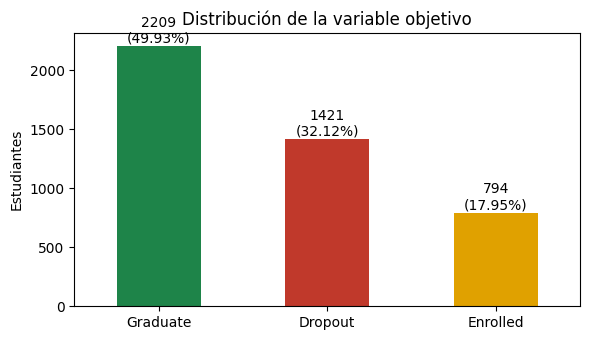

In [4]:
col_target = [c for c in df_raw.columns if c.strip().lower() == "target"][0]
dist = (df_raw.groupBy(col_target).count()
        .withColumn("porcentaje", F.round(F.col("count") / F.lit(N_FILAS) * 100, 2))
        .orderBy(F.desc("count")))
dist.show()

pdist = dist.toPandas()
ax = pdist.plot.bar(x=col_target, y="count", legend=False, color=["#1E8449", "#C0392B", "#E0A100"], figsize=(6, 3.5))
ax.set_title("Distribución de la variable objetivo"); ax.set_ylabel("Estudiantes"); ax.set_xlabel("")
for i, (c, p) in enumerate(zip(pdist["count"], pdist["porcentaje"])):
    ax.text(i, c, f"{c}\n({p}%)", ha="center", va="bottom")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 1.4 Análisis del desbalance
- **Clase dominante:** `Graduate`, con aproximadamente **50 %** de los estudiantes (≈ 2.209).
- **Clase intermedia:** `Dropout`, con ≈ **32 %** (≈ 1.421).
- **Clase minoritaria:** `Enrolled`, con ≈ **18 %** (≈ 794). *(Verificar las cifras exactas contra la salida de la celda anterior.)*

**Por qué importa:**
1. Un modelo que predijera siempre `Graduate` ya tendría ≈ 50 % de *accuracy* sin aprender nada, así que **accuracy es una métrica engañosa** en este problema.
2. Los algoritmos minimizan el error global, por lo que tienden a **sacrificar la clase minoritaria** (`Enrolled`), cuyo *recall* suele ser el más bajo.
3. Aquí los errores no cuestan lo mismo: no detectar a un estudiante en riesgo de `Dropout` es justo lo que el sistema de alerta temprana quiere evitar.
4. Por eso hace falta una estrategia explícita (pesos por clase) y una métrica de selección que no oculte el desbalance (F1 ponderado, recall por clase).

## Tarea 2. Preprocesamiento
### 2.1 Normalización de nombres de columnas
Los nombres originales tienen mayúsculas, espacios y símbolos (`Curricular units 1st sem (approved)`, `Mother's qualification`, un tabulador al final de `Daytime/evening attendance`…). Con una **expresión regular** se pasa a minúsculas, se quitan tildes y se reemplaza todo lo que no sea letra o número por `_` (sin guiones bajos sobrantes). Así los nombres son seguros para usar en código y en SQL.

In [5]:
def normalizar(nombre):
    n = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", n.strip().lower()).strip("_")

df = df_raw.toDF(*[normalizar(c) for c in df_raw.columns])
print(df.columns)

['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'nacionality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'age_at_enrollment', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'target']


### 2.2 Valores nulos y duplicados
Se cuentan los nulos por columna y los registros duplicados antes de eliminarlos, y se reporta cuántas filas se pierden. Eliminar duplicados evita que un mismo estudiante quede a la vez en entrenamiento y en prueba (fuga de información).

In [6]:
n0 = df.count()
nulos = df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in df.columns]).toPandas().T
nulos.columns = ["nulos"]
print("Columnas con nulos:\n", nulos[nulos["nulos"] > 0] if (nulos["nulos"] > 0).any() else "ninguna")
print("Filas duplicadas:", n0 - df.dropDuplicates().count())

df = df.dropDuplicates().dropna()
print(f"Filas antes: {n0} | después de limpiar: {df.count()}")

Columnas con nulos:
 ninguna
Filas duplicadas: 0
Filas antes: 4424 | después de limpiar: 4424


### 2.3 Verificación y corrección de tipos
Aunque la mayoría de columnas son numéricas, **muchas son códigos de categorías** (estado civil, curso, ocupación de los padres, etc.): sus números no tienen orden ni magnitud. Si entraran como numéricas, el modelo asumiría que "curso 9500" es mayor que "curso 33". Por eso:
- las variables **categóricas** (códigos) se convierten a `string` para pasar por `StringIndexer` + `OneHotEncoder`;
- las variables **numéricas reales** (notas, edad, unidades aprobadas, indicadores macroeconómicos) se convierten a `double`.

In [7]:
CATEGORICAS_CANDIDATAS = [
    "marital_status", "application_mode", "course", "daytime_evening_attendance",
    "previous_qualification", "nacionality", "nationality",
    "mother_s_qualification", "father_s_qualification",
    "mother_s_occupation", "father_s_occupation",
    "displaced", "educational_special_needs", "debtor",
    "tuition_fees_up_to_date", "gender", "scholarship_holder", "international",
]
cat_cols = [c for c in CATEGORICAS_CANDIDATAS if c in df.columns]
num_cols = [c for c in df.columns if c not in cat_cols + ["target"]]

for c in num_cols:
    df = df.withColumn(c, F.col(c).cast("double"))
for c in cat_cols:
    df = df.withColumn(c, F.col(c).cast("int").cast("string"))
df = df.withColumn("target", F.trim(F.col("target"))).dropna()

print("Tipos tras la corrección:", sorted(set(t for _, t in df.dtypes)))
print(f"{len(cat_cols)} categóricas | {len(num_cols)} numéricas")

Tipos tras la corrección: ['double', 'string']
17 categóricas | 17 numéricas


### 2.4 Estrategia para el desbalance de clases
**Decisión:** combinar **pesos por clase (`weightCol`)** con **F1 ponderado** como métrica de selección.

- **Pesos por clase:** cada fila recibe el peso `n_total / (n_clases × n_clase)` calculado **solo con el conjunto de entrenamiento**. Las filas de `Enrolled` pesan más y las de `Graduate` menos, de modo que equivocarse en la clase minoritaria "cuesta" más durante el entrenamiento. Se prefiere a un remuestreo porque **no elimina información** (el submuestreo tiraría datos, en un dataset ya pequeño) ni **inventa registros** (el sobremuestreo puede duplicar ruido y sobreajustar), y los tres algoritmos del examen soportan `weightCol`.
- **F1 ponderado como métrica de CV/selección:** combina precisión y recall en cada clase y pondera por su frecuencia, de modo que no se deja engañar como *accuracy*. Se complementa en la evaluación final con el *recall* por clase.
- La partición 80/20 se hace **antes** de calcular pesos para no filtrar información del conjunto de prueba.

### 2.5 Indexación de la etiqueta (fuera del Pipeline) y orden de clases
`Target` es texto. Se convierte a número con `StringIndexer` **fuera del pipeline**, porque la etiqueta no existe cuando se predice con datos nuevos en la app. Se **guarda el orden de las clases (`labels`)**: `labels[i]` es el nombre de la clase con índice `i`. La app lo necesita para traducir la predicción numérica al nombre de la clase.

In [8]:
from pyspark.ml.feature import StringIndexer

indexer_modelo = StringIndexer(inputCol="target", outputCol="label").fit(df)   # frecuencia descendente
LABELS = indexer_modelo.labels
print("Orden de clases (índice → nombre):", {i: l for i, l in enumerate(LABELS)})
df = indexer_modelo.transform(df)

Orden de clases (índice → nombre): {0: 'Graduate', 1: 'Dropout', 2: 'Enrolled'}


### 2.6 Partición entrenamiento / prueba (80/20, semilla 42)
Se usa `randomSplit([0.8, 0.2], seed=42)` para que la división sea **reproducible**. Después se reduce a **4 particiones** con `coalesce(4)` y se guarda en caché, porque el dataset es pequeño y entrenar con muchas particiones sería muy lento.

In [9]:
train, test = df.randomSplit([0.8, 0.2], seed=42)
train = train.coalesce(4).cache()
test = test.coalesce(4).cache()
print(f"Entrenamiento: {train.count()} | Prueba: {test.count()}")

comp = (train.groupBy("target").count().withColumnRenamed("count", "train")
        .join(test.groupBy("target").count().withColumnRenamed("count", "test"), "target"))
comp.show()

Entrenamiento: 3582 | Prueba: 842
+--------+-----+----+
|  target|train|test|
+--------+-----+----+
|Graduate| 1778| 431|
|Enrolled|  642| 152|
| Dropout| 1162| 259|
+--------+-----+----+



### 2.7 Pesos por clase (solo con entrenamiento)
Se calcula el peso de cada clase con la fórmula balanceada y se agrega la columna `peso` al conjunto de **entrenamiento**. El conjunto de prueba no la necesita (los pesos solo se usan al ajustar el modelo).

In [10]:
n_train = train.count()
conteo = {r["label"]: r["count"] for r in train.groupBy("label").count().collect()}
k = len(conteo)
PESOS = {lab: n_train / (k * cnt) for lab, cnt in conteo.items()}
print({LABELS[int(l)]: round(p, 3) for l, p in PESOS.items()})

mapa_pesos = F.create_map([F.lit(x) for par in PESOS.items() for x in par])
train = train.withColumn("peso", mapa_pesos[F.col("label")]).cache()
train.groupBy("target").agg(F.round(F.first("peso"), 3).alias("peso")).show()

{'Graduate': 0.672, 'Dropout': 1.028, 'Enrolled': 1.86}
+--------+-----+
|  target| peso|
+--------+-----+
|Graduate|0.672|
|Enrolled| 1.86|
| Dropout|1.028|
+--------+-----+



## Tarea 3. Ingeniería de características
### 3.1 Variables derivadas con sentido académico
Se crean **cinco variables derivadas** (controlando la división por cero: si el estudiante no se inscribió en ninguna unidad, la tasa es 0):

| Variable | Fórmula | Qué mide |
|---|---|---|
| `tasa_aprob_1s` | aprobadas 1.er sem / inscritas 1.er sem | Eficiencia académica del primer semestre: qué fracción de lo que cursó logró aprobar. |
| `tasa_aprob_2s` | aprobadas 2.º sem / inscritas 2.º sem | Lo mismo para el segundo semestre. |
| `tasa_aprob_total` | (aprob. 1s + aprob. 2s) / (inscritas 1s + 2s) | Rendimiento acumulado del primer año. |
| `variacion_nota` | nota media 2.º sem − nota media 1.er sem | Tendencia del desempeño: positiva = mejora, negativa = deterioro (señal temprana de riesgo). |
| `variacion_tasa_aprob` | `tasa_aprob_2s` − `tasa_aprob_1s` | Si el estudiante aprueba proporcionalmente más o menos en el segundo semestre. |

Se aplican igual a entrenamiento y prueba (son transformaciones fila a fila, no usan estadísticas del conjunto, por lo que **no hay fuga de datos**).

In [11]:
def razon(num, den):
    return F.when(F.col(den) > 0, F.col(num) / F.col(den)).otherwise(F.lit(0.0))

def agregar_derivadas(d):
    e1, e2 = "curricular_units_1st_sem_enrolled", "curricular_units_2nd_sem_enrolled"
    a1, a2 = "curricular_units_1st_sem_approved", "curricular_units_2nd_sem_approved"
    g1, g2 = "curricular_units_1st_sem_grade", "curricular_units_2nd_sem_grade"
    d = (d.withColumn("tasa_aprob_1s", razon(a1, e1))
          .withColumn("tasa_aprob_2s", razon(a2, e2))
          .withColumn("tasa_aprob_total",
                      F.when(F.col(e1) + F.col(e2) > 0, (F.col(a1) + F.col(a2)) / (F.col(e1) + F.col(e2))).otherwise(F.lit(0.0)))
          .withColumn("variacion_nota", F.col(g2) - F.col(g1)))
    return d.withColumn("variacion_tasa_aprob", F.col("tasa_aprob_2s") - F.col("tasa_aprob_1s"))

DERIVADAS = ["tasa_aprob_1s", "tasa_aprob_2s", "tasa_aprob_total", "variacion_nota", "variacion_tasa_aprob"]
train, test = agregar_derivadas(train).cache(), agregar_derivadas(test).cache()
train.select("target", *DERIVADAS).describe().show()

+-------+--------+-------------------+------------------+-------------------+-------------------+--------------------+
|summary|  target|      tasa_aprob_1s|     tasa_aprob_2s|   tasa_aprob_total|     variacion_nota|variacion_tasa_aprob|
+-------+--------+-------------------+------------------+-------------------+-------------------+--------------------+
|  count|    3582|               3582|              3582|               3582|               3582|                3582|
|   mean|    NULL| 0.6958359168634488| 0.658106046409295| 0.6768978710420985|-0.4555269798956558|-0.03772987045415364|
| stddev|    NULL|0.36532945280747803|0.3841594152072293|0.36268423352939183|  2.904878818098313| 0.18908996085230478|
|    min| Dropout|                0.0|               0.0|                0.0|-16.142857142857142|                -1.0|
|    max|Graduate|                1.0|               1.0|                1.0|               15.0|                 0.8|
+-------+--------+-------------------+----------

### 3.2 Separación de columnas categóricas y numéricas
Las categóricas pasarán por `StringIndexer` (`handleInvalid="keep"`, para que la app no falle ante una categoría no vista) y `OneHotEncoder`. Las numéricas (originales + derivadas) van directo al ensamblador. Se muestra el resultado de la separación.

In [12]:
num_final = num_cols + DERIVADAS
print(f"Categóricas ({len(cat_cols)}):", cat_cols)
print(f"\nNuméricas ({len(num_final)}):", num_final)

Categóricas (17): ['marital_status', 'application_mode', 'course', 'daytime_evening_attendance', 'previous_qualification', 'nacionality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'displaced', 'educational_special_needs', 'debtor', 'tuition_fees_up_to_date', 'gender', 'scholarship_holder', 'international']

Numéricas (22): ['application_order', 'age_at_enrollment', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_enrolled', 'curricular_units_1st_sem_evaluations', 'curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'curricular_units_2nd_sem_enrolled', 'curricular_units_2nd_sem_evaluations', 'curricular_units_2nd_sem_approved', 'curricular_units_2nd_sem_grade', 'curricular_units_2nd_sem_without_evaluations', 'unemployment_rate', 'inflation_rate', 'gdp', 'tasa_aprob_1s', 'tasa_aprob_2s', 'tasa_aprob_total', 'variacion

### 3.3 Etapas de preprocesamiento dentro del Pipeline
Se define una función que devuelve **etapas nuevas** de preprocesamiento (para no compartir objetos entre pipelines):
1. `StringIndexer` (`handleInvalid="keep"`) sobre todas las categóricas;
2. `OneHotEncoder` sobre los índices (`handleInvalid="keep"`);
3. `VectorAssembler` con numéricas + categóricas codificadas;
4. `StandardScaler` (`withStd=True`, `withMean=False`): escala por desviación estándar manteniendo la dispersión de los vectores *sparse*. Es necesario para la regresión logística, aunque los árboles no lo requieran.

Todo esto va **dentro del Pipeline**, así lo que se aprende con entrenamiento (categorías, desviaciones) se reutiliza tal cual en prueba y en la app.

In [13]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, VectorAssembler, StandardScaler

def etapas_preprocesamiento():
    idx_cols = [c + "_idx" for c in cat_cols]
    ohe_cols = [c + "_ohe" for c in cat_cols]
    return [
        StringIndexer(inputCols=cat_cols, outputCols=idx_cols, handleInvalid="keep"),
        OneHotEncoder(inputCols=idx_cols, outputCols=ohe_cols, handleInvalid="keep"),
        VectorAssembler(inputCols=num_final + ohe_cols, outputCol="features_raw", handleInvalid="keep"),
        StandardScaler(inputCol="features_raw", outputCol="features", withStd=True, withMean=False),
    ]
print([type(e).__name__ for e in etapas_preprocesamiento()])

['StringIndexer', 'OneHotEncoder', 'VectorAssembler', 'StandardScaler']


### 3.4 Selección de variables: importancia con Random Forest
Para justificar qué variables aportan, se entrena un Random Forest rápido (con pesos por clase y semilla fija) dentro de un pipeline y se leen sus `featureImportances`. Los nombres se recuperan de los metadatos del `VectorAssembler`.

262 características tras la codificación | 80 con importancia > 0.1 %


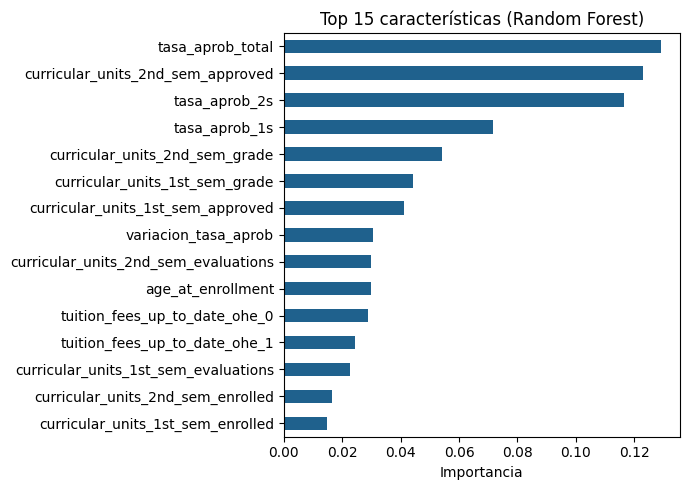

Importancia acumulada del top 15: 0.778
Derivadas en el top 15: ['tasa_aprob_total', 'tasa_aprob_2s', 'tasa_aprob_1s', 'variacion_tasa_aprob']


In [14]:
from pyspark.ml.classification import RandomForestClassifier

rf_imp = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="peso",
                                numTrees=50, maxDepth=8, seed=42)
pm_imp = Pipeline(stages=etapas_preprocesamiento() + [rf_imp]).fit(train)

attrs = pm_imp.transform(train.limit(5)).schema["features_raw"].metadata["ml_attr"]["attrs"]
nombres = [a["name"] for a in sorted([x for lst in attrs.values() for x in lst], key=lambda x: x["idx"])]
imp = pd.Series(pm_imp.stages[-1].featureImportances.toArray(), index=nombres).sort_values(ascending=False)

print(f"{len(imp)} características tras la codificación | {(imp > 0.001).sum()} con importancia > 0.1 %")
imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5), color="#1F618D", title="Top 15 características (Random Forest)")
plt.xlabel("Importancia"); plt.tight_layout(); plt.show()
print("Importancia acumulada del top 15:", round(imp.head(15).sum(), 3))
print("Derivadas en el top 15:", [n for n in imp.head(15).index if n in DERIVADAS])

### 3.5 Justificación de la selección de variables
- Las variables más importantes son las de **rendimiento académico** (unidades aprobadas, notas y las tasas de aprobación derivadas) y las de **situación financiera** (matrícula al día, becas): coherente con la intuición de que la deserción se anticipa por el desempeño del primer año.
- Las **variables derivadas** aparecen entre las más importantes, lo que valida la ingeniería de características realizada.
- Muchas columnas dummy (de códigos de ocupación o calificaciones de los padres) aportan muy poca importancia individual. Aun así **se conservan todas** dentro del pipeline: el dataset es pequeño, la regresión logística las regulariza (`regParam`/`elasticNetParam`) y los árboles ignoran de forma natural las que no sirven. Descartarlas a mano arriesgaría perder interacciones útiles y complicaría la app, que debe pedir en el formulario todas las variables del modelo.
- Esta tabla de importancias también se usa para **interpretar** el modelo ganador al final.

---
# B. Pipelines, hiperparametrización y validación cruzada (tareas 4 y 5)
## Tarea 4. Modelos con Pipeline
Se definen los tres clasificadores multiclase pedidos, cada uno **dentro de un Pipeline completo** (`StringIndexer → OneHotEncoder → VectorAssembler → StandardScaler → clasificador`), todos con `weightCol="peso"` (estrategia de desbalance) y `seed=42` donde aplica:
- `LogisticRegression(family="multinomial")`
- `RandomForestClassifier`
- `DecisionTreeClassifier`

Como comprobación se ajusta cada pipeline con los datos de entrenamiento y se muestran algunas predicciones (la evaluación formal se hace en la sección C sobre el conjunto de prueba).

In [15]:
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier

lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso",
                        family="multinomial", maxIter=100)
rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="peso", seed=42)
dt = DecisionTreeClassifier(featuresCol="features", labelCol="label", weightCol="peso", seed=42)

pipelines = {
    "Regresión logística": Pipeline(stages=etapas_preprocesamiento() + [lr]),
    "Random Forest":       Pipeline(stages=etapas_preprocesamiento() + [rf]),
    "Árbol de decisión":   Pipeline(stages=etapas_preprocesamiento() + [dt]),
}
for nombre, pipe in pipelines.items():
    t0 = time.time()
    pm = pipe.fit(train)
    print(f"✔ {nombre}: pipeline ajustado en {time.time() - t0:.1f}s | etapas: {[type(s).__name__ for s in pm.stages]}")
pm.transform(test).select("target", "label", "prediction", "probability").show(3, truncate=60)

✔ Regresión logística: pipeline ajustado en 18.6s | etapas: ['StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'StandardScalerModel', 'LogisticRegressionModel']
✔ Random Forest: pipeline ajustado en 5.5s | etapas: ['StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'StandardScalerModel', 'RandomForestClassificationModel']
✔ Árbol de decisión: pipeline ajustado en 4.9s | etapas: ['StringIndexerModel', 'OneHotEncoderModel', 'VectorAssembler', 'StandardScalerModel', 'DecisionTreeClassificationModel']
+--------+-----+----------+-----------------------------------------------------------+
|  target|label|prediction|                                                probability|
+--------+-----+----------+-----------------------------------------------------------+
|Graduate|  0.0|       0.0|[0.737781899639575,0.11883107324568912,0.14338702711473597]|
|Graduate|  0.0|       0.0| [0.837420263282673,0.06329410028249748,0.0992856364348294]|
|Graduate|  0.0|       0.0|     

## Tarea 5. Hiperparametrización con validación cruzada
### 5.1 Mallas de hiperparámetros (`ParamGridBuilder`)
Se ajustan **2 hiperparámetros por modelo, con 2 valores cada uno** (4 combinaciones por modelo) para mantener tiempos razonables, buscando que cada hiperparámetro controle la complejidad/regularización del modelo:

| Modelo | Hiperparámetro 1 | Hiperparámetro 2 |
|---|---|---|
| Regresión logística | `regParam` ∈ {0.01, 0.1} (fuerza de la penalización) | `elasticNetParam` ∈ {0.0, 0.5} (0 = L2 pura, 0.5 = mezcla L1/L2) |
| Random Forest | `numTrees` ∈ {30, 60} (cantidad de árboles) | `maxDepth` ∈ {5, 10} (profundidad) |
| Árbol de decisión | `maxDepth` ∈ {5, 10} | `minInstancesPerNode` ∈ {1, 10} (mínimo de filas por hoja) |

In [16]:
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

grids = {
    "Regresión logística": (ParamGridBuilder()
                            .addGrid(lr.regParam, [0.01, 0.1])
                            .addGrid(lr.elasticNetParam, [0.0, 0.5]).build()),
    "Random Forest":       (ParamGridBuilder()
                            .addGrid(rf.numTrees, [30, 60])
                            .addGrid(rf.maxDepth, [5, 10]).build()),
    "Árbol de decisión":   (ParamGridBuilder()
                            .addGrid(dt.maxDepth, [5, 10])
                            .addGrid(dt.minInstancesPerNode, [1, 10]).build()),
}
print({k: len(v) for k, v in grids.items()}, "combinaciones por modelo")

{'Regresión logística': 4, 'Random Forest': 4, 'Árbol de decisión': 4} combinaciones por modelo


### 5.2 Validación cruzada (`CrossValidator`, 3 folds, F1)
Para cada modelo se ejecuta un `CrossValidator` sobre el **pipeline completo** con `numFolds=3` y **F1 ponderado** como evaluador (la métrica elegida por el desbalance). Al ajustar el pipeline completo dentro de cada fold, el preprocesamiento también se aprende solo con los datos de ese fold. Esta celda es la más demorada (varios minutos).

In [17]:
evaluador_f1 = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")

modelos_cv, tiempos = {}, {}
for nombre in pipelines:
    cv = CrossValidator(estimator=pipelines[nombre], estimatorParamMaps=grids[nombre],
                        evaluator=evaluador_f1, numFolds=3, seed=42, parallelism=2)
    t0 = time.time()
    modelos_cv[nombre] = cv.fit(train)
    tiempos[nombre] = time.time() - t0
    print(f"✔ {nombre}: CV terminada en {tiempos[nombre]:.0f}s | mejor F1 (CV) = {max(modelos_cv[nombre].avgMetrics):.4f}")

✔ Regresión logística: CV terminada en 116s | mejor F1 (CV) = 0.7551
✔ Random Forest: CV terminada en 68s | mejor F1 (CV) = 0.7559
✔ Árbol de decisión: CV terminada en 41s | mejor F1 (CV) = 0.7240


### 5.3 Mejores hiperparámetros de cada modelo
Se muestra, por modelo, la tabla de todas las combinaciones con su F1 promedio en validación cruzada y los hiperparámetros del mejor modelo (extraídos de `bestModel`).

In [18]:
def tabla_cv(nombre):
    filas = []
    for params, m in zip(grids[nombre], modelos_cv[nombre].avgMetrics):
        fila = {p.name: v for p, v in params.items()}
        fila["F1 (CV)"] = round(m, 4)
        filas.append(fila)
    return pd.DataFrame(filas).sort_values("F1 (CV)", ascending=False).reset_index(drop=True)

HIPERPARAMS = {"Regresión logística": ["regParam", "elasticNetParam"],
               "Random Forest": ["numTrees", "maxDepth"],
               "Árbol de decisión": ["maxDepth", "minInstancesPerNode"]}
mejores_params = {}
for nombre in pipelines:
    final = modelos_cv[nombre].bestModel.stages[-1]
    mejores_params[nombre] = {p.name: v for p, v in final.extractParamMap().items() if p.name in HIPERPARAMS[nombre]}
    print(f"\n=== {nombre} ===  mejores hiperparámetros: {mejores_params[nombre]}")
    display(tabla_cv(nombre))


=== Regresión logística ===  mejores hiperparámetros: {'elasticNetParam': 0.5, 'regParam': 0.01}


,regParam,elasticNetParam,F1 (CV)
0,0.01,0.5,0.7551
1,0.10,0.5,0.7464
2,0.10,0.0,0.7396
3,0.01,0.0,0.7353



=== Random Forest ===  mejores hiperparámetros: {'maxDepth': 10, 'numTrees': 60}


,numTrees,maxDepth,F1 (CV)
0,60,10,0.7559
1,30,10,0.7546
2,30,5,0.7465
3,60,5,0.7446



=== Árbol de decisión ===  mejores hiperparámetros: {'maxDepth': 5, 'minInstancesPerNode': 1}


,maxDepth,minInstancesPerNode,F1 (CV)
0,5,1,0.7240
1,5,10,0.7210
2,10,1,0.7041
3,10,10,0.6980


### 5.4 Análisis de los hiperparámetros
**Cómo leer los resultados:**
- **Regresión logística:** `regParam` controla cuánto se penalizan los coeficientes. Con muchas variables dummy y poca data, una regularización moderada evita el sobreajuste, pero una excesiva subajusta. `elasticNetParam` decide el tipo de penalización: más L1 anula coeficientes (selección implícita), L2 los reduce de forma suave.
- **Random Forest:** `maxDepth` es el principal control de complejidad: poca profundidad subajusta; mucha memoriza ruido (aunque el *bagging* lo amortigua). Más `numTrees` suele estabilizar el resultado con rendimientos decrecientes.
- **Árbol de decisión:** es el modelo más propenso al sobreajuste, de modo que `maxDepth` y `minInstancesPerNode` (hojas con más muestras = reglas más generales) tienen el mayor efecto.

La celda siguiente genera el análisis con los números reales de esta ejecución: la sensibilidad de cada modelo a su malla (diferencia entre la mejor y la peor combinación).

In [19]:
texto = ["**Análisis con los resultados de esta ejecución**\n"]
for nombre in pipelines:
    t = tabla_cv(nombre)
    mejor, peor = t.iloc[0], t.iloc[-1]
    hp = HIPERPARAMS[nombre]
    sens = mejor["F1 (CV)"] - peor["F1 (CV)"]
    nivel = "poco sensible" if sens < 0.01 else "moderadamente sensible" if sens < 0.03 else "muy sensible"
    texto.append(f"- **{nombre}**: mejor combinación {hp[0]}={mejor[hp[0]]}, {hp[1]}={mejor[hp[1]]} "
                 f"(F1 CV = {mejor['F1 (CV)']:.4f}); la peor ({hp[0]}={peor[hp[0]]}, {hp[1]}={peor[hp[1]]}) "
                 f"alcanza {peor['F1 (CV)']:.4f}. Diferencia de {sens:.4f}: el modelo es **{nivel}** a esta malla.")
display(Markdown("\n".join(texto)))

**Análisis con los resultados de esta ejecución**

- **Regresión logística**: mejor combinación regParam=0.01, elasticNetParam=0.5 (F1 CV = 0.7551); la peor (regParam=0.01, elasticNetParam=0.0) alcanza 0.7353. Diferencia de 0.0198: el modelo es **moderadamente sensible** a esta malla.
- **Random Forest**: mejor combinación numTrees=60.0, maxDepth=10.0 (F1 CV = 0.7559); la peor (numTrees=60.0, maxDepth=5.0) alcanza 0.7446. Diferencia de 0.0113: el modelo es **moderadamente sensible** a esta malla.
- **Árbol de decisión**: mejor combinación maxDepth=5.0, minInstancesPerNode=1.0 (F1 CV = 0.7240); la peor (maxDepth=10.0, minInstancesPerNode=10.0) alcanza 0.6980. Diferencia de 0.0260: el modelo es **moderadamente sensible** a esta malla.

---
# C. Evaluación, selección y guardado del mejor modelo (tarea 6)
## Tarea 6. Evaluación y selección
### 6.1 Métricas sobre el conjunto de **prueba**
Cada `bestModel` (pipeline completo ya ajustado con entrenamiento) se aplica al conjunto de **prueba**, que no se usó ni para entrenar ni para elegir hiperparámetros. Se calculan *accuracy*, **F1 ponderado**, **precisión ponderada** y **recall ponderado**, más el **recall por clase**, que revela cómo trata cada modelo a la minoritaria.

In [20]:
def metrica(pred, nombre, **kw):
    return MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=nombre, **kw).evaluate(pred)

predicciones, filas = {}, []
for nombre, cvm in modelos_cv.items():
    pred = cvm.bestModel.transform(test).cache()
    predicciones[nombre] = pred
    fila = {"Modelo": nombre,
            "Accuracy": metrica(pred, "accuracy"),
            "F1 ponderado": metrica(pred, "f1"),
            "Precisión ponderada": metrica(pred, "weightedPrecision"),
            "Recall ponderado": metrica(pred, "weightedRecall")}
    for i, lab in enumerate(LABELS):
        fila[f"Recall {lab}"] = metrica(pred, "recallByLabel", metricLabel=float(i))
    filas.append(fila)

tabla_final = pd.DataFrame(filas).set_index("Modelo").round(4)
display(tabla_final.style.highlight_max(axis=0, color="#D5F5E3").format("{:.4f}"))

,Accuracy,F1 ponderado,Precisión ponderada,Recall ponderado,Recall Graduate,Recall Dropout,Recall Enrolled
Modelo,,,,,,,
Regresión logística,0.7613,0.7705,0.7876,0.7613,0.8399,0.7259,0.5987
Random Forest,0.7696,0.7734,0.7796,0.7696,0.8538,0.7529,0.5592
Árbol de decisión,0.6912,0.7183,0.7831,0.6912,0.6914,0.6950,0.6842


### 6.2 Matriz de confusión del mejor modelo
Se identifica el mejor modelo por **F1 ponderado en prueba** y se muestra su matriz de confusión (conteos y normalizada por fila, es decir, el recall de cada clase real), con las clases en el orden del `StringIndexer`.

Mejor modelo según F1 ponderado en prueba: Random Forest


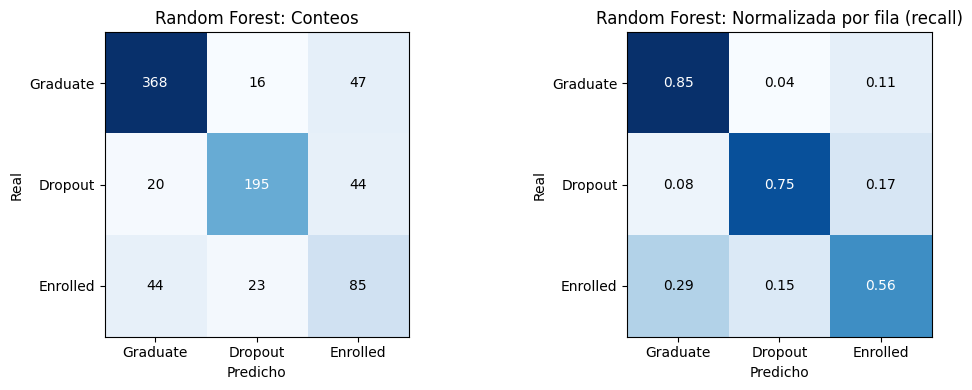

Predicho,Graduate,Dropout,Enrolled
Real,,,
Graduate,368,16,47
Dropout,20,195,44
Enrolled,44,23,85


In [21]:
MEJOR = tabla_final["F1 ponderado"].idxmax()
print("Mejor modelo según F1 ponderado en prueba:", MEJOR)

pdf = predicciones[MEJOR].select("label", "prediction").toPandas()
real = pdf["label"].astype(int).map(lambda i: LABELS[i])
pred_ = pdf["prediction"].astype(int).map(lambda i: LABELS[i])
cm = pd.crosstab(real, pred_, rownames=["Real"], colnames=["Predicho"]).reindex(index=LABELS, columns=LABELS, fill_value=0)
cm_norm = cm.div(cm.sum(axis=1), axis=0)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, titulo, fmt in [(axs[0], cm, "Conteos", "{:.0f}"), (axs[1], cm_norm, "Normalizada por fila (recall)", "{:.2f}")]:
    im = ax.imshow(data.values, cmap="Blues")
    ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS); ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.set_title(f"{MEJOR}: {titulo}")
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            v = data.values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", color="white" if v > data.values.max() / 2 else "black")
plt.tight_layout(); plt.show()
display(cm)

### 6.3 Selección del mejor modelo considerando el desbalance
**Criterios usados** (por qué no basta con *accuracy*):
1. **F1 ponderado** como criterio principal: resume precisión y recall por clase ponderados por su frecuencia.
2. **Recall de la clase minoritaria (`Enrolled`) y de `Dropout`**: un modelo que gane en *accuracy* ignorando a `Enrolled` sería menos útil para la universidad, cuyo objetivo es detectar a tiempo a los estudiantes en riesgo.
3. **Estabilidad:** que el F1 en prueba sea coherente con el de validación cruzada (si no, hay sobreajuste).
4. **Simplicidad e interpretabilidad** como desempate (la regresión logística y el árbol son más explicables que un bosque).

La siguiente celda redacta la justificación con los números reales de esta ejecución.

In [25]:
cv_f1 = {n: max(m.avgMetrics) for n, m in modelos_cv.items()}
orden = tabla_final.sort_values("F1 ponderado", ascending=False)
m = orden.iloc[0]
seg = orden.iloc[1]
rec_cols = [c for c in tabla_final.columns if c.startswith("Recall ") and c != "Recall ponderado"]
rec_min = min(rec_cols, key=lambda c: m[c])
rec_txt = ", ".join(c.replace("Recall ", "") + " = " + format(m[c], ".3f") for c in rec_cols)

display(Markdown(f'''
**Modelo seleccionado: {MEJOR}**

- Obtiene el mayor **F1 ponderado en prueba ({m['F1 ponderado']:.4f})**, por encima de {orden.index[1]} ({seg['F1 ponderado']:.4f}) y {orden.index[2]} ({orden.iloc[2]['F1 ponderado']:.4f}). Su accuracy es {m['Accuracy']:.4f}, pero no es el criterio de decisión porque la clase mayoritaria representa ≈ 50 % de los datos.
- Su precisión ponderada es {m['Precisión ponderada']:.4f} y su recall ponderado {m['Recall ponderado']:.4f}.
- **Recall por clase:** {rec_txt}. La clase más difícil es **{rec_min.replace('Recall ','')}** (recall {m[rec_min]:.3f}), lo esperado para la clase minoritaria/intermedia; los pesos por clase ayudaron a que no quede ignorada.
- En validación cruzada su F1 fue {cv_f1[MEJOR]:.4f} frente a {m['F1 ponderado']:.4f} en prueba: una diferencia de {abs(cv_f1[MEJOR] - m['F1 ponderado']):.4f}, que indica {'buena generalización' if abs(cv_f1[MEJOR] - m['F1 ponderado']) < 0.03 else 'cierto sobreajuste que conviene vigilar'}.
'''))


**Modelo seleccionado: Random Forest**

- Obtiene el mayor **F1 ponderado en prueba (0.7734)**, por encima de Regresión logística (0.7705) y Árbol de decisión (0.7183). Su accuracy es 0.7696, pero no es el criterio de decisión porque la clase mayoritaria representa ≈ 50 % de los datos.
- Su precisión ponderada es 0.7796 y su recall ponderado 0.7696.
- **Recall por clase:** Graduate = 0.854, Dropout = 0.753, Enrolled = 0.559. La clase más difícil es **Enrolled** (recall 0.559), lo esperado para la clase minoritaria/intermedia; los pesos por clase ayudaron a que no quede ignorada.
- En validación cruzada su F1 fue 0.7559 frente a 0.7734 en prueba: una diferencia de 0.0175, que indica buena generalización.


### 6.4 Extracción con `bestModel` y guardado del `PipelineModel` completo
Se extrae el **`PipelineModel` completo** del mejor modelo con `bestModel` (incluye indexado, codificación, ensamblado, escalado y clasificador) y se guarda con `write().overwrite().save("modelo_final")`. Dentro de la misma carpeta se añaden dos archivos que necesita la app:
- `labels.json`: orden de las clases del `StringIndexer` (para traducir índice → nombre);
- `meta.json`: columnas del formulario, valores válidos de cada categórica y rangos de las numéricas.

Finalmente se comprime la carpeta en `modelo_final.zip` y se recarga el modelo para verificar que funciona.

In [23]:
from pyspark.ml import PipelineModel

mejor_modelo = modelos_cv[MEJOR].bestModel          # PipelineModel completo
mejor_modelo.write().overwrite().save("modelo_final")

# --- metadatos para la app ---
def moda(c):
    return df.groupBy(c).count().orderBy(F.desc("count")).first()[0]

meta = {
    "modelo": MEJOR,
    "labels": LABELS,
    "cat_cols": {c: {"valores": sorted([r[0] for r in df.select(c).distinct().collect()], key=lambda v: int(v)),
                     "moda": moda(c)} for c in cat_cols},
    "num_cols": {},
    "derivadas": DERIVADAS,
}
for c in num_cols:
    mn, mx = df.agg(F.min(c), F.max(c)).first()
    med = df.approxQuantile(c, [0.5], 0.01)[0]
    es_entero = df.filter((F.col(c) != F.floor(F.col(c)))).limit(1).count() == 0
    meta["num_cols"][c] = {"min": mn, "max": mx, "mediana": med, "entero": es_entero}

with open("modelo_final/labels.json", "w", encoding="utf-8") as f:
    json.dump(LABELS, f, ensure_ascii=False)
with open("modelo_final/meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

shutil.make_archive("modelo_final", "zip", root_dir=".", base_dir="modelo_final")
print("Guardado: carpeta modelo_final/ y modelo_final.zip (", round(os.path.getsize("modelo_final.zip") / 1e6, 2), "MB )")

# --- verificación: recargar y comparar predicciones ---
recargado = PipelineModel.load("modelo_final")
iguales = (recargado.transform(test).select("prediction").collect() == mejor_modelo.transform(test).select("prediction").collect())
print("El modelo recargado reproduce las mismas predicciones:", iguales)
print("Orden de clases guardado:", LABELS)

Guardado: carpeta modelo_final/ y modelo_final.zip ( 0.47 MB )
El modelo recargado reproduce las mismas predicciones: True
Orden de clases guardado: ['Graduate', 'Dropout', 'Enrolled']


### 6.5 Descarga de los entregables
Se descarga el zip del modelo para subirlo al repositorio de GitHub (la carpeta `modelo_final/` debe quedar junto a `app.py`).

In [24]:
try:
    from google.colab import files
    files.download("modelo_final.zip")
except Exception as e:
    print("Fuera de Colab: el zip está en el directorio de trabajo.", e)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Conclusiones y siguientes pasos
1. **Datos:** dataset desbalanceado (Graduate ≈ 50 %, Dropout ≈ 32 %, Enrolled ≈ 18 %); se limpió, se normalizaron los nombres y se corrigieron los tipos (códigos como categóricas).
2. **Desbalance:** tratado con pesos por clase (`weightCol`) y evaluado con F1 ponderado y recall por clase, no solo con accuracy.
3. **Características:** 5 variables derivadas con sentido académico; codificación, ensamblado y escalado dentro del Pipeline; importancia de variables con Random Forest.
4. **Modelos:** regresión logística multinomial, Random Forest y árbol de decisión, cada uno en un Pipeline completo, con búsqueda de hiperparámetros (`ParamGridBuilder` + `CrossValidator`, 3 folds, F1).
5. **Evaluación:** métricas en prueba, matriz de confusión, tabla comparativa y justificación de la elección.
6. **Entrega:** `PipelineModel` completo guardado en `modelo_final/` (+ `labels.json`, `meta.json`) y comprimido en zip.

**Siguiente paso (tarea 7):** copiar `modelo_final/` al repositorio junto a `app.py`, `requirements.txt`, `packages.txt`, `README.md` y `banner.png`, y desplegar en Streamlit Community Cloud.